xT assigns each pitch location an estimate of future scoring value. The map below comes from a small, deterministic toy model; it makes the Bellman-style calculation visible without embedding match data. The model input PRESS consumes is an xT grid created from event data. [@singh2018xt]

## Definition and calculation

Singh’s original formulation groups passes and dribbles into a move branch. This project separates pass and carry and includes an explicit zero-value loss outcome; that extension and its smoothing are **own derivation**. For location i, the implementation iterates the action-value equation: `xT_i = p_shot,i × p_goal,i + p_pass,i × Σ_j T_pass(i,j) xT_j + p_carry,i × Σ_j T_carry(i,j) xT_j`. A possession loss contributes zero future value; therefore action probabilities need not sum to one across shot, pass, and carry. Transition matrices describe destination locations conditional on a continuing pass/carry; their action probabilities include the rate of successful continuation. The loss probability completes the normalization. [@singh2018xt] The event-derived probabilities, spatial bins, and smoothing used by the project pipeline are implemented in the sibling analysis repository's `xt_library.py`; the toy code below demonstrates the iteration, not a refit of the match grid. **own derivation**

## Runnable toy example

The code calculates every value shown in the heatmap. It uses synthetic probabilities and transition matrices, clearly separated from the match-trained xT grid used by PRESS.

Converged toy xT values: 6; iterations: 90


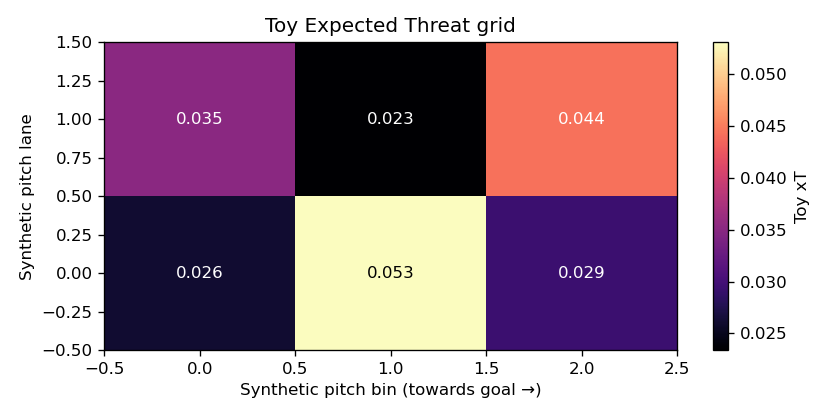

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Six synthetic locations arranged as a 3 × 2 pitch grid.
p_shot=np.array([0.02,0.04,0.12,0.01,0.03,0.10])
p_goal=np.array([0.04,0.08,0.18,0.03,0.06,0.15])
p_pass=np.array([0.55,0.60,0.35,0.58,0.62,0.38])
p_carry=np.array([0.30,0.22,0.28,0.32,0.23,0.30])

# Row-stochastic toy destination distributions conditional on pass/carry.
T_pass=np.array([[.5,.3,.1,.1,0,0],[.1,.5,.3,0,.1,0],[0,.1,.7,0,0,.2],[.4,0,0,.4,.2,0],[0,.3,0,.1,.5,.1],[0,0,.2,0,.2,.6]])
T_carry=np.array([[.5,.2,0,.3,0,0],[0,.4,.3,0,.3,0],[0,0,.7,0,0,.3],[.4,0,0,.4,.2,0],[0,.3,0,.1,.4,.2],[0,0,.2,0,.2,.6]])

xt=np.zeros(6)
for _ in range(1000):
    updated=p_shot*p_goal+p_pass*(T_pass@xt)+p_carry*(T_carry@xt)
    if np.max(np.abs(updated-xt))<1e-12:
        xt=updated
        break
    xt=updated
else:
    raise RuntimeError("Toy xT value iteration did not converge")
# PRESS expects (n_x, n_y); plotting transposes to (n_y, n_x).
xt_grid=xt.reshape(3,2)

fig,ax=plt.subplots(figsize=(7,3.5))
im=ax.imshow(xt_grid.T,origin='lower',cmap='magma',aspect='auto')
for row in range(2):
    for col in range(3):
        ax.text(col,row,f'{xt_grid[col,row]:.3f}',ha='center',va='center',color='black' if xt_grid[col,row] > 0.045 else 'white')
ax.set(xlabel='Synthetic pitch bin (towards goal →)',ylabel='Synthetic pitch lane',title='Toy Expected Threat grid')
fig.colorbar(im,ax=ax,label='Toy xT')
fig.tight_layout()
out=Path('figures/vignette_11_expected_threat.png'); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix('.svg'))
print(f'Converged toy xT values: {xt_grid.size}; iterations: {_+1}')

## Using the match-derived grid

The end-to-end [match usage guide](../../../usage.qmd) loads the project grid from `skillcorner-analysis/results/xt/xt_grid.npy` and passes it to the transition and action-selection models. That grid is built from event-derived shot, pass, carry, and loss rates using the xT value iteration above, with spatial smoothing in the project pipeline. [@singh2018xt] **own derivation**

## References

Singh, K. (2018). *Introducing Expected Threat (xT).* [Project description](https://karun.in/blog/expected-threat.html). [@singh2018xt]

## Use an xT grid in PRESS

The grid shape is `(n_x, n_y)` and the pitch origin is its centre. `get_xt_values` mirrors coordinates to evaluate the attacking team and opponent in their respective directions. This example uses the grid computed above. In research, load the event-derived `xt_grid.npy`; the xT extra is a demonstration of the calculation, not a replacement for fitting that grid.


In [6]:
from PRESS.utils.state import get_xt_values
# Synthetic target positions on a centred 105 × 68 m pitch.
targets = np.array([[-35., -17.], [0., 17.], [35., -17.]])
team_xt, opponent_xt = get_xt_values(targets, "left_to_right", xt_grid)
print("xT grid (n_x, n_y):", xt_grid.shape)
print("target xT:", team_xt)
print("opponent xT:", opponent_xt)
# A direct linear-system solution independently checks this toy iteration.
Q = p_pass[:, None] * T_pass + p_carry[:, None] * T_carry
exact = np.linalg.solve(np.eye(6) - Q, p_shot * p_goal)
print("iteration residual:", float(np.max(np.abs(xt - exact))))


xT grid (n_x, n_y): (3, 2)
target xT: [0.02611704 0.02340429 0.02931451]
opponent xT: [0.04425545 0.05303273 0.03514167]
iteration residual: 2.6586961798802378e-12
